# Stage 5: ML Forecasting

## Objective

Do new-character banners improve the monthly revenue forecast?

This stage forecasts monthly GLOBAL mobile revenue of Genshin Impact and Honkai: Star Rail. ARIMA (one model per game) is the baseline; ARIMAX adds the banner variables to the same ARIMA models; LightGBM, pooled over both games, is run with and without banner variables. All approaches are evaluated with rolling-origin one-month-ahead forecasts over the last 12 months (RMSE, MAPE). All tables and figures are written to `outputs/stage5/`.

| Step | Task |
|---|---|
| 1 | Merge revenue and banner calendar, data summary |
| 2 | ARIMA baseline and ARIMAX (ARIMA with banner variables), one model per game |
| 3 | LightGBM pooled over both games, with and without banner variables |
| 4 | Evaluation: RMSE, MAPE, forecast plot |

Inputs in `Dataset/` (collected by hand from public websites; sources in `Dataset/stage5_sources.md`): `revenue_monthly.csv` and `banner_calendar.csv`.
Run the notebook from the `Data_Analysis` folder (**Restart and Run All**).

## 0. Setup

In [1]:
import itertools
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, kpss

%matplotlib inline
warnings.filterwarnings("ignore")

DATA = Path("../Dataset")                    # input data
OUT = Path("../outputs/stage5")
TAB, FIG = OUT / "tables", OUT / "figures"
assert (DATA / "revenue_monthly.csv").exists(), "Run the notebook from the Data_Analysis folder"
TAB.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

TEST_MONTHS = 12   # last 12 months are used for evaluation
print("Data:", DATA.resolve())
print("Outputs:", OUT.resolve())

Data: D:\STAT3013_repo\Dataset
Outputs: D:\STAT3013_repo\outputs\stage5


## 1. S5.2 – Build the Stage 5 dataset

1. Merge `revenue_monthly.csv` and `banner_calendar.csv` on GAME and MONTH (each month must appear in both files exactly once).
2. Add `IS_APPROX = 1` for months up to 2024-10 (figures rounded to the nearest million, risk K07).
3. Save `Dataset/stage5_data.csv` and a data summary `outputs/stage5/tables/stage5_data_summary.csv` (data summary and banner-variable counts).

In [2]:
APPROX_UNTIL = "2024-10"   # last month with revenue rounded to the nearest million

revenue = pd.read_csv(DATA / "revenue_monthly.csv")
banner = pd.read_csv(DATA / "banner_calendar.csv")

data = revenue.merge(banner, on=["GAME", "MONTH"], how="outer", validate="one_to_one", indicator=True)
assert (data["_merge"] == "both").all(), data[data["_merge"] != "both"]
data = data.drop(columns="_merge").rename(columns={"NOTE": "REVENUE_NOTE"})
data["IS_APPROX"] = (data["MONTH"] <= APPROX_UNTIL).astype(int)

cols = ["GAME", "MONTH", "GLOBAL", "BANNER", "HOT_CHAR", "PROMO_EVENT", "IS_APPROX",
        "CN", "CN_EST", "VERSION", "NEW_5STAR", "EVENT_NOTE", "REVENUE_NOTE"]
data = data[cols].sort_values(["GAME", "MONTH"])
assert data[["GLOBAL", "BANNER", "HOT_CHAR", "PROMO_EVENT"]].notna().all().all(), "Missing values in main columns"
data.to_csv(DATA / "stage5_data.csv", index=False, encoding="utf-8")

summary_data = data.groupby("GAME").agg(
    FIRST_MONTH=("MONTH", "min"),
    LAST_MONTH=("MONTH", "max"),
    N_MONTHS=("MONTH", "count"),
    MIN_REVENUE_million_USD=("GLOBAL", lambda s: s.min() / 1e6),
    MAX_REVENUE_million_USD=("GLOBAL", lambda s: s.max() / 1e6),
    IS_APPROX_MONTHS=("IS_APPROX", "sum"),
    BANNER_MONTHS=("BANNER", "sum"),
    HOT_CHAR_MONTHS=("HOT_CHAR", "sum"),
    PROMO_EVENT_MONTHS=("PROMO_EVENT", "sum"),
).round(2).reset_index()
summary_data.to_csv(TAB / "stage5_data_summary.csv", index=False)

print("Rows:", len(data))
summary_data

Rows: 88


,GAME,FIRST_MONTH,LAST_MONTH,N_MONTHS,MIN_REVENUE_million_USD,MAX_REVENUE_million_USD,IS_APPROX_MONTHS,BANNER_MONTHS,HOT_CHAR_MONTHS,PROMO_EVENT_MONTHS
0,Genshin,2022-12,2026-09,46,11.06,68.0,23,34,34,4
1,HSR,2023-04,2026-09,42,5.00,81.0,19,31,40,6


## 2. S5.3 – ARIMA baseline

- Model **log(revenue)** to reduce the influence of spike months; forecasts are exponentiated back to USD.
- **d**: ADF (H0: non-stationary) and KPSS (H0: stationary). d = 0 only if both indicate stationarity, otherwise d = 1. Both tests are repeated on the differenced series as a check.
- **p, q** ∈ {0, 1, 2}: lowest AIC on the initial training part (last 12 months held out).
- **Ljung–Box** test on the residuals (p > 0.05 = no remaining autocorrelation).
- Rolling-origin one-month-ahead forecasts for the last 12 months (expanding window).
- **ARIMAX:** the same (p, d, q) with BANNER, HOT_CHAR and PROMO_EVENT of month t as exogenous regressors (known in advance because version schedules are announced), evaluated with the same rolling origin.

In [3]:
ALPHA = 0.05
data_arima = pd.read_csv(DATA / "stage5_data.csv")
data_arima["MONTH"] = pd.PeriodIndex(data_arima["MONTH"], freq="M")


def choose_d(y):
    """d = 0 if ADF rejects a unit root and KPSS does not reject stationarity; otherwise d = 1."""
    adf_p = adfuller(y, autolag="AIC")[1]
    kpss_p = kpss(y, regression="c", nlags="auto")[1]
    d = 0 if (adf_p < ALPHA and kpss_p >= ALPHA) else 1
    return d, adf_p, kpss_p


def choose_pq(y, d):
    """Fit ARIMA(p, d, q) for p, q in {0, 1, 2} and return the one with the lowest AIC."""
    best = None
    for p, q in itertools.product(range(3), range(3)):
        try:
            res = ARIMA(y, order=(p, d, q), trend="c" if d == 0 else "n").fit()
        except Exception:
            continue
        if best is None or res.aic < best[2]:
            best = (p, q, res.aic)
    return best


EXOG = ["BANNER", "HOT_CHAR", "PROMO_EVENT"]   # banner variables for ARIMAX

configs, forecasts = [], []
arimax_forecasts, arimax_coefs = [], []
for game, g in data_arima.groupby("GAME"):
    g = g.sort_values("MONTH").reset_index(drop=True)
    y = np.log(g["GLOBAL"].to_numpy(dtype=float))
    X = g[EXOG].to_numpy(dtype=float)
    n_train = len(y) - TEST_MONTHS

    d, adf_p, kpss_p = choose_d(y[:n_train])
    # Re-check after first differencing (reported only; does not change how d is chosen)
    y_diff = np.diff(y[:n_train])
    adf_diff_p = adfuller(y_diff, autolag="AIC")[1]
    kpss_diff_p = kpss(y_diff, regression="c", nlags="auto")[1]
    p, q, aic = choose_pq(y[:n_train], d)
    trend = "c" if d == 0 else "n"

    # Residual check on the initial training fit
    fit0 = ARIMA(y[:n_train], order=(p, d, q), trend=trend).fit()
    lb_lag = min(10, n_train // 4)
    lb_p = float(acorr_ljungbox(fit0.resid[d:], lags=[lb_lag])["lb_pvalue"].iloc[0])

    # Rolling-origin one-month-ahead forecasts
    for i in range(n_train, len(y)):
        res = ARIMA(y[:i], order=(p, d, q), trend=trend).fit()
        pred = float(np.exp(res.forecast(1)[0]))
        forecasts.append({
            "GAME": game,
            "MONTH": str(g.loc[i, "MONTH"]),
            "ORIGIN": str(g.loc[i - 1, "MONTH"]),
            "ACTUAL": g.loc[i, "GLOBAL"],
            "FORECAST": round(pred),
            "MODEL": f"ARIMA({p},{d},{q})",
        })

    # ARIMAX: same (p, d, q) plus the banner variables of month t as exogenous regressors
    fitx = ARIMA(y[:n_train], exog=X[:n_train], order=(p, d, q), trend=trend).fit()
    lbx_p = float(acorr_ljungbox(fitx.resid[d:], lags=[lb_lag])["lb_pvalue"].iloc[0])
    # statsmodels puts the exogenous coefficients first, in the order of EXOG
    for k, name in enumerate(EXOG):
        arimax_coefs.append({"GAME": game, "VARIABLE": name,
                             "COEF": round(float(fitx.params[k]), 4),
                             "P_VALUE": round(float(fitx.pvalues[k]), 4)})
    arimax_coefs.append({"GAME": game, "VARIABLE": "LJUNGBOX_P", "COEF": None, "P_VALUE": round(lbx_p, 4)})
    for i in range(n_train, len(y)):
        resx = ARIMA(y[:i], exog=X[:i], order=(p, d, q), trend=trend).fit()
        predx = float(np.exp(resx.forecast(1, exog=X[i:i + 1])[0]))
        arimax_forecasts.append({
            "GAME": game,
            "MONTH": str(g.loc[i, "MONTH"]),
            "ORIGIN": str(g.loc[i - 1, "MONTH"]),
            "ACTUAL": g.loc[i, "GLOBAL"],
            "FORECAST": round(predx),
            "MODEL": f"ARIMAX({p},{d},{q})",
        })

    configs.append({
        "GAME": game, "N_MONTHS": len(y), "N_TRAIN_INITIAL": n_train,
        "TRANSFORM": "log", "ORDER": f"({p},{d},{q})", "TREND": trend, "AIC": round(aic, 2),
        "ADF_P": round(adf_p, 4), "KPSS_P": round(kpss_p, 4),
        "ADF_DIFF_P": round(adf_diff_p, 4), "KPSS_DIFF_P": round(kpss_diff_p, 4),
        "LJUNGBOX_LAG": lb_lag, "LJUNGBOX_P": round(lb_p, 4),
    })

cfg_arima = pd.DataFrame(configs)
fc_arima = pd.DataFrame(forecasts)
cfg_arima.to_csv(TAB / "stage5_arima_config.csv", index=False)
fc_arima.to_csv(TAB / "stage5_arima_forecasts.csv", index=False)
fc_arimax = pd.DataFrame(arimax_forecasts)
fc_arimax.to_csv(TAB / "stage5_arimax_forecasts.csv", index=False)
coef_arimax = pd.DataFrame(arimax_coefs)
coef_arimax.to_csv(TAB / "stage5_arimax_coefs.csv", index=False)
display(coef_arimax)   # ARIMAX coefficients of the banner variables
cfg_arima   # ARIMA configuration table

,GAME,VARIABLE,COEF,P_VALUE
0,Genshin,BANNER,-0.0650,0.7349
1,Genshin,HOT_CHAR,0.2189,0.1834
2,Genshin,PROMO_EVENT,0.0487,0.8785
3,Genshin,LJUNGBOX_P,NaN,0.6414
4,HSR,BANNER,0.1477,0.4739
5,HSR,HOT_CHAR,0.4264,0.8198
6,HSR,PROMO_EVENT,0.6010,0.0843
7,HSR,LJUNGBOX_P,NaN,0.4726


,GAME,N_MONTHS,N_TRAIN_INITIAL,TRANSFORM,ORDER,TREND,AIC,ADF_P,KPSS_P,ADF_DIFF_P,KPSS_DIFF_P,LJUNGBOX_LAG,LJUNGBOX_P
0,Genshin,46,34,log,"(1,1,2)",n,22.92,0.9290,0.0100,0.0251,0.0417,8,0.7892
1,HSR,42,30,log,"(0,1,1)",n,38.56,0.0001,0.0212,0.0025,0.0728,7,0.7685


,RMSE_USD,MAPE_%
GAME,,
Genshin,6957988.27,28.29
HSR,7601068.42,53.70


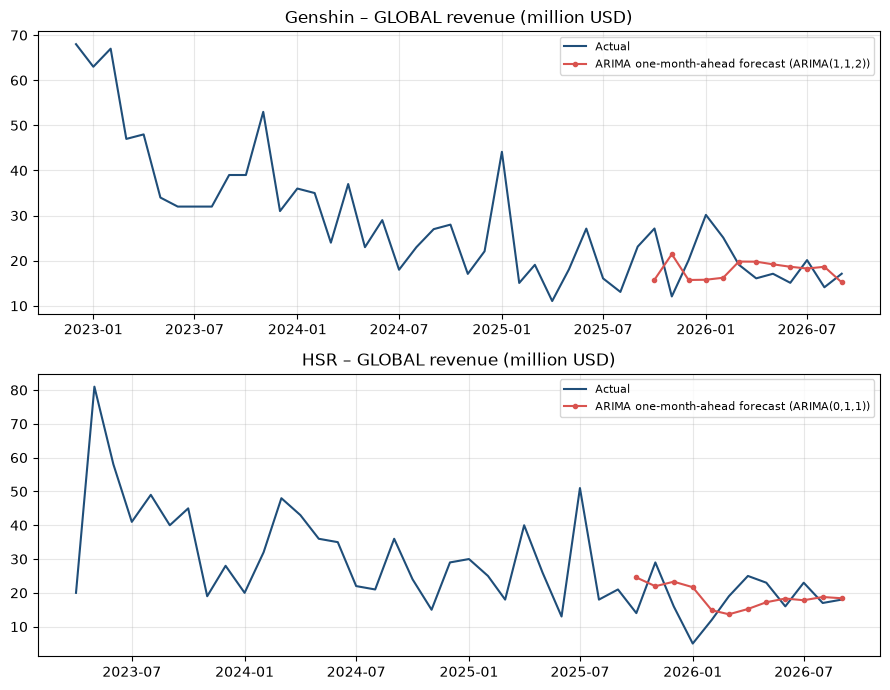

In [4]:
# Quick look at the errors and plot (the formal evaluation is in step 4)
err = fc_arima["FORECAST"] - fc_arima["ACTUAL"]
display(fc_arima.assign(ERR=err).groupby("GAME").apply(lambda t: pd.Series({
    "RMSE_USD": np.sqrt((t["ERR"] ** 2).mean()),
    "MAPE_%": (t["ERR"].abs() / t["ACTUAL"]).mean() * 100,
}), include_groups=False).round(2))

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=False)
for ax, (game, g) in zip(axes, data_arima.groupby("GAME")):
    g = g.sort_values("MONTH")
    f = fc_arima[fc_arima["GAME"] == game]
    ax.plot(g["MONTH"].dt.to_timestamp(), g["GLOBAL"] / 1e6, color="#1f4e79", label="Actual")
    ax.plot(pd.PeriodIndex(f["MONTH"], freq="M").to_timestamp(), f["FORECAST"] / 1e6,
            color="#d9534f", marker="o", ms=3, label=f"ARIMA one-month-ahead forecast ({f['MODEL'].iloc[0]})")
    ax.set_title(f"{game} – GLOBAL revenue (million USD)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "arima_forecast.png", dpi=150)
plt.show()

## 3. S5.4 – LightGBM (pooled over both games)

- Target: log(revenue in month t).
- **Without banner:** LAG1, LAG2, LAG3 (log revenue 1–3 months earlier) + GAME.
- **With banner:** the above + BANNER, HOT_CHAR, PROMO_EVENT of month t (version schedules are announced before the month starts).
- Rolling origin over the last 12 months: train on every month before the target month (both games), then forecast it.
- Parameters fixed in advance (small data): shallow trees, fixed seed so reruns give identical results.

In [5]:
SEED = 42
PARAMS = dict(
    objective="regression",
    n_estimators=200,
    learning_rate=0.05,
    max_depth=2,
    num_leaves=4,
    min_child_samples=5,
    subsample=1.0,
    colsample_bytree=1.0,
    random_state=SEED,
    deterministic=True,
    force_col_wise=True,
    verbose=-1,
)
BASE_FEATURES = ["LAG1", "LAG2", "LAG3", "GAME_HSR"]
BANNER_FEATURES = ["BANNER", "HOT_CHAR", "PROMO_EVENT"]
VERSIONS = {
    "LGBM_no_banner": BASE_FEATURES,
    "LGBM_banner": BASE_FEATURES + BANNER_FEATURES,
}
LABELS = {"LGBM_no_banner": "LightGBM without banner", "LGBM_banner": "LightGBM with banner"}

# Prepare data
data_lgbm = pd.read_csv(DATA / "stage5_data.csv")
data_lgbm["MONTH"] = pd.PeriodIndex(data_lgbm["MONTH"], freq="M")
data_lgbm = data_lgbm.sort_values(["GAME", "MONTH"]).reset_index(drop=True)
data_lgbm["Y"] = np.log(data_lgbm["GLOBAL"].astype(float))
data_lgbm["GAME_HSR"] = (data_lgbm["GAME"] == "HSR").astype(int)
for k in (1, 2, 3):
    data_lgbm[f"LAG{k}"] = data_lgbm.groupby("GAME")["Y"].shift(k)
model_data = data_lgbm.dropna(subset=["LAG1", "LAG2", "LAG3"]).reset_index(drop=True)

last_month = model_data["MONTH"].max()
test_months = pd.period_range(last_month - TEST_MONTHS + 1, last_month, freq="M")

# Rolling origin
rows = []
for name, feats in VERSIONS.items():
    for m in test_months:
        train = model_data[model_data["MONTH"] < m]
        test = model_data[model_data["MONTH"] == m]
        model = lgb.LGBMRegressor(**PARAMS).fit(train[feats], train["Y"])
        pred = np.exp(model.predict(test[feats]))
        for (_, r), p in zip(test.iterrows(), pred):
            rows.append({
                "GAME": r["GAME"], "MONTH": str(m), "ORIGIN": str(m - 1),
                "ACTUAL": r["GLOBAL"], "FORECAST": round(float(p)),
                "MODEL": name, "N_TRAIN": len(train),
            })
fc_lgbm = pd.DataFrame(rows)
fc_lgbm.to_csv(TAB / "stage5_lgbm_forecasts.csv", index=False)

# Configuration
pd.DataFrame([{"MODEL": n, "FEATURES": "; ".join(f), "TARGET": "log(GLOBAL)",
               **{k: v for k, v in PARAMS.items() if k not in ("verbose", "force_col_wise")}}
              for n, f in VERSIONS.items()]).to_csv(TAB / "stage5_lgbm_config.csv", index=False)

initial_train = model_data[model_data["MONTH"] < test_months[0]]
print("Training rows at the first origin:", len(initial_train))

Training rows at the first origin: 58


In [6]:
# Feature importance (gain) on all data before the evaluation period
imp = []
for name, feats in VERSIONS.items():
    mdl = lgb.LGBMRegressor(**PARAMS, importance_type="gain").fit(initial_train[feats], initial_train["Y"])
    for f, g in zip(feats, mdl.feature_importances_):
        imp.append({"MODEL": name, "FEATURE": f, "GAIN": round(float(g), 4)})
imp = pd.DataFrame(imp)
imp["GAIN_SHARE_%"] = (imp["GAIN"] / imp.groupby("MODEL")["GAIN"].transform("sum") * 100).round(1)
imp.to_csv(TAB / "stage5_lgbm_importance.csv", index=False)
imp

,MODEL,FEATURE,GAIN,GAIN_SHARE_%
0,LGBM_no_banner,LAG1,20.1873,34.4
1,LGBM_no_banner,LAG2,14.9944,25.5
2,LGBM_no_banner,LAG3,22.6654,38.6
3,LGBM_no_banner,GAME_HSR,0.8672,1.5
4,LGBM_banner,LAG1,16.6437,23.2
5,LGBM_banner,LAG2,13.8943,19.3
6,LGBM_banner,LAG3,19.5577,27.2
7,LGBM_banner,GAME_HSR,1.6043,2.2
8,LGBM_banner,BANNER,10.4638,14.6
9,LGBM_banner,HOT_CHAR,5.0682,7.1


RMSE_USD  MAPE_%
MODEL          GAME                       
LGBM_banner    Genshin  6425362.86   30.32
               HSR      8236060.30   54.90
LGBM_no_banner Genshin  7127601.76   32.76
               HSR      8188194.01   58.36

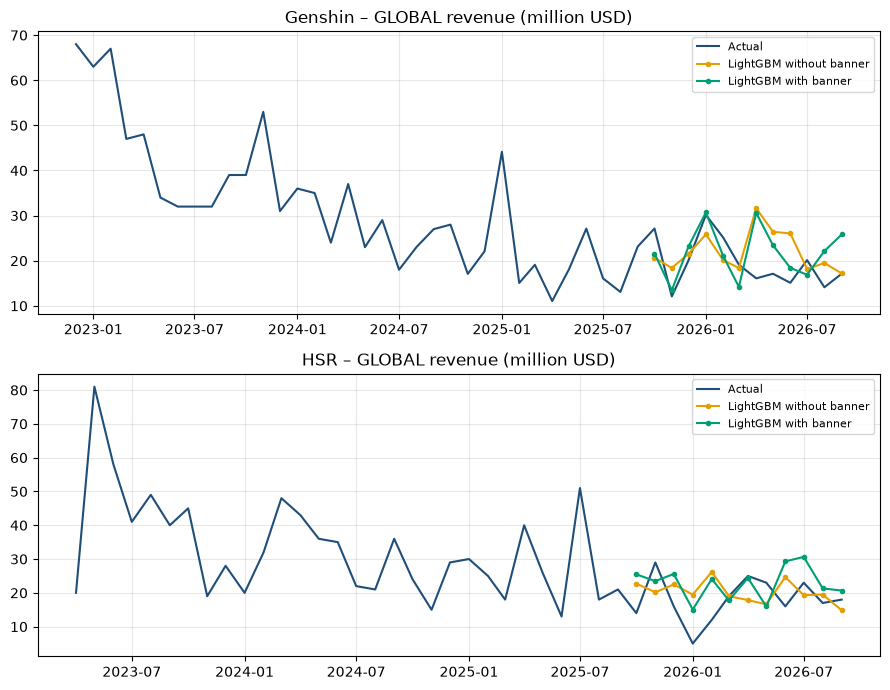

In [7]:
# Quick look at the errors and plot (the formal evaluation is in step 4)
err = fc_lgbm["FORECAST"] - fc_lgbm["ACTUAL"]
display(fc_lgbm.assign(ERR=err).groupby(["MODEL", "GAME"]).apply(lambda t: pd.Series({
    "RMSE_USD": np.sqrt((t["ERR"] ** 2).mean()),
    "MAPE_%": (t["ERR"].abs() / t["ACTUAL"]).mean() * 100,
}), include_groups=False).round(2))

colors = {"LGBM_no_banner": "#e69f00", "LGBM_banner": "#009e73"}
fig, axes = plt.subplots(2, 1, figsize=(9, 7))
for ax, (game, g) in zip(axes, data_lgbm.groupby("GAME")):
    ax.plot(g["MONTH"].dt.to_timestamp(), g["GLOBAL"] / 1e6, color="#1f4e79", label="Actual")
    for name in VERSIONS:
        f = fc_lgbm[(fc_lgbm["GAME"] == game) & (fc_lgbm["MODEL"] == name)]
        ax.plot(pd.PeriodIndex(f["MONTH"], freq="M").to_timestamp(), f["FORECAST"] / 1e6,
                color=colors[name], marker="o", ms=3, label=LABELS[name])
    ax.set_title(f"{game} – GLOBAL revenue (million USD)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "lightgbm_forecast.png", dpi=150)
plt.show()

## 4. S5.5 – Evaluation

- Check that the four approaches forecast the same 12 months with the same actual values.
- **RMSE** = √(mean of (forecast − actual)²), in USD.
- **MAPE** = mean of |forecast − actual| / actual × 100, in %.
- Effect of the banner variables: ARIMAX vs ARIMA, LightGBM with vs without banner, and LightGBM with banner vs ARIMA (% change in RMSE, percentage-point change in MAPE).
- Forecast plot: actual revenue and the four forecast lines.

In [8]:
NAMES = {
    "ARIMA": "ARIMA",
    "ARIMAX": "ARIMAX (ARIMA with banner)",
    "LGBM_no_banner": "LightGBM without banner",
    "LGBM_banner": "LightGBM with banner",
}

arima = pd.read_csv(TAB / "stage5_arima_forecasts.csv")
arima["MODEL"] = "ARIMA"
arimax = pd.read_csv(TAB / "stage5_arimax_forecasts.csv")
arimax["MODEL"] = "ARIMAX"
lgbm = pd.read_csv(TAB / "stage5_lgbm_forecasts.csv")
cols = ["GAME", "MONTH", "ACTUAL", "FORECAST", "MODEL"]
fc = pd.concat([arima[cols], arimax[cols], lgbm[cols]], ignore_index=True)

# Same months and actual values for all approaches
check = fc.groupby(["GAME", "MONTH"]).agg(n_model=("MODEL", "nunique"), n_actual=("ACTUAL", "nunique"))
assert (check["n_model"] == len(NAMES)).all(), "Some months are missing a forecast from one approach"
assert (check["n_actual"] == 1).all(), "Actual values differ between approaches"
assert fc.groupby(["GAME", "MODEL"]).size().eq(12).all(), "Each approach must have exactly 12 months per game"

wide = fc.pivot_table(index=["GAME", "MONTH", "ACTUAL"], columns="MODEL", values="FORECAST").reset_index()
wide = wide[["GAME", "MONTH", "ACTUAL"] + list(NAMES)]
wide.to_csv(TAB / "stage5_forecasts_all.csv", index=False)

# RMSE and MAPE by game and approach
fc["ERR"] = fc["FORECAST"] - fc["ACTUAL"]
metrics = (fc.groupby(["GAME", "MODEL"])
             .apply(lambda t: pd.Series({
                 "RMSE_million_USD": np.sqrt((t["ERR"] ** 2).mean()) / 1e6,
                 "MAPE_%": (t["ERR"].abs() / t["ACTUAL"]).mean() * 100,
             }), include_groups=False)
             .reset_index())
metrics["MODEL"] = pd.Categorical(metrics["MODEL"], categories=list(NAMES), ordered=True)
metrics = metrics.sort_values(["GAME", "MODEL"])
metrics["APPROACH"] = metrics["MODEL"].map(NAMES)
metrics[["GAME", "APPROACH", "RMSE_million_USD", "MAPE_%"]].round(2).to_csv(TAB / "stage5_metrics.csv", index=False)
metrics[["GAME", "APPROACH", "RMSE_million_USD", "MAPE_%"]].round(2)

,GAME,APPROACH,RMSE_million_USD,MAPE_%
0,Genshin,ARIMA,6.96,28.29
1,Genshin,ARIMAX (ARIMA with banner),6.16,27.28
3,Genshin,LightGBM without banner,7.13,32.76
2,Genshin,LightGBM with banner,6.43,30.32
4,HSR,ARIMA,7.60,53.70
5,HSR,ARIMAX (ARIMA with banner),5.97,35.45
7,HSR,LightGBM without banner,8.19,58.36
6,HSR,LightGBM with banner,8.24,54.90


In [9]:
# Effect of adding banner variables
m = metrics.set_index(["GAME", "MODEL"])
COMPARISONS = [("ARIMAX", "ARIMA"),               # banner effect within ARIMA
               ("LGBM_banner", "LGBM_no_banner"),  # banner effect within LightGBM
               ("LGBM_banner", "ARIMA")]
cmp_rows = []
for game in metrics["GAME"].unique():
    for model, ref in COMPARISONS:
        b = m.loc[(game, model)]
        r = m.loc[(game, ref)]
        cmp_rows.append({
            "GAME": game,
            "MODEL": NAMES[model],
            "COMPARED_WITH": NAMES[ref],
            "RMSE_change_%": (b["RMSE_million_USD"] / r["RMSE_million_USD"] - 1) * 100,
            "MAPE_change_pp": b["MAPE_%"] - r["MAPE_%"],
        })
cmp = pd.DataFrame(cmp_rows).round(1)
cmp.to_csv(TAB / "stage5_banner_effect.csv", index=False)
cmp

,GAME,MODEL,COMPARED_WITH,RMSE_change_%,MAPE_change_pp
0,Genshin,ARIMAX (ARIMA with banner),ARIMA,-11.4,-1.0
1,Genshin,LightGBM with banner,LightGBM without banner,-9.9,-2.4
2,Genshin,LightGBM with banner,ARIMA,-7.7,2.0
3,HSR,ARIMAX (ARIMA with banner),ARIMA,-21.4,-18.3
4,HSR,LightGBM with banner,LightGBM without banner,0.6,-3.5
5,HSR,LightGBM with banner,ARIMA,8.4,1.2


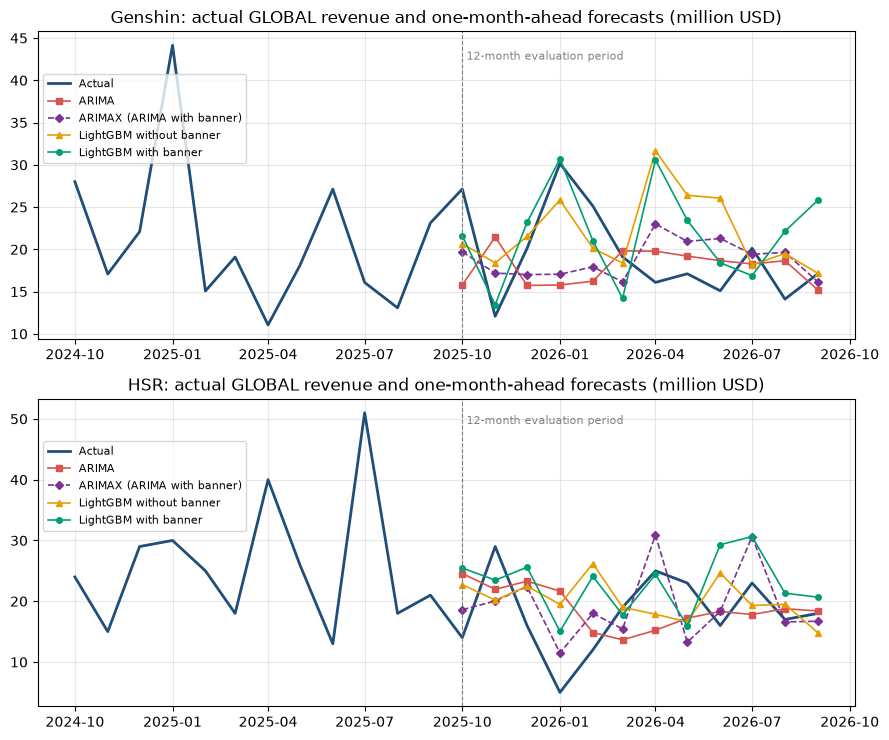

In [10]:
# Forecast plot: actual revenue and the four approaches
plot_data = pd.read_csv(DATA / "stage5_data.csv")
plot_data["MONTH"] = pd.PeriodIndex(plot_data["MONTH"], freq="M").to_timestamp()
style = {
    "ARIMA": dict(color="#d9534f", marker="s"),
    "ARIMAX": dict(color="#7b3294", marker="D", ls="--"),
    "LGBM_no_banner": dict(color="#e69f00", marker="^"),
    "LGBM_banner": dict(color="#009e73", marker="o"),
}
fig, axes = plt.subplots(2, 1, figsize=(9, 7.5))
for ax, (game, g) in zip(axes, plot_data.groupby("GAME")):
    g = g[g["MONTH"] >= pd.Timestamp("2024-10-01")]
    ax.plot(g["MONTH"], g["GLOBAL"] / 1e6, color="#1f4e79", lw=2, label="Actual")
    for key, label in NAMES.items():
        f = fc[(fc["GAME"] == game) & (fc["MODEL"] == key)]
        ax.plot(pd.PeriodIndex(f["MONTH"], freq="M").to_timestamp(), f["FORECAST"] / 1e6,
                ms=4, lw=1.2, label=label, **style[key])
    ax.axvline(pd.Timestamp("2025-10-01"), color="grey", ls="--", lw=0.8)
    ax.text(pd.Timestamp("2025-10-05"), ax.get_ylim()[1] * 0.95, "12-month evaluation period",
            fontsize=8, color="grey", va="top")
    ax.set_title(f"{game}: actual GLOBAL revenue and one-month-ahead forecasts (million USD)")
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(0, 0.88))
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "forecast_comparison.png", dpi=150)
plt.show()

## 5. Input variables of each approach

The target is always log GLOBAL revenue of month t.

| Approach | Input variables | Number |
|---|---|---|
| ARIMA | Past revenue of the same game only | 1 series |
| ARIMAX | Past revenue + BANNER, HOT_CHAR, PROMO_EVENT | 1 series + 3 |
| LightGBM without banner | LAG1, LAG2, LAG3, GAME | 4 |
| LightGBM with banner | LAG1, LAG2, LAG3, GAME, BANNER, HOT_CHAR, PROMO_EVENT | 7 |

ARIMA uses only log revenue (one variable); ARIMAX adds the three banner variables as exogenous regressors.
The two figures below show the banner variables over time and how much each variable contributes to ARIMAX and LightGBM.

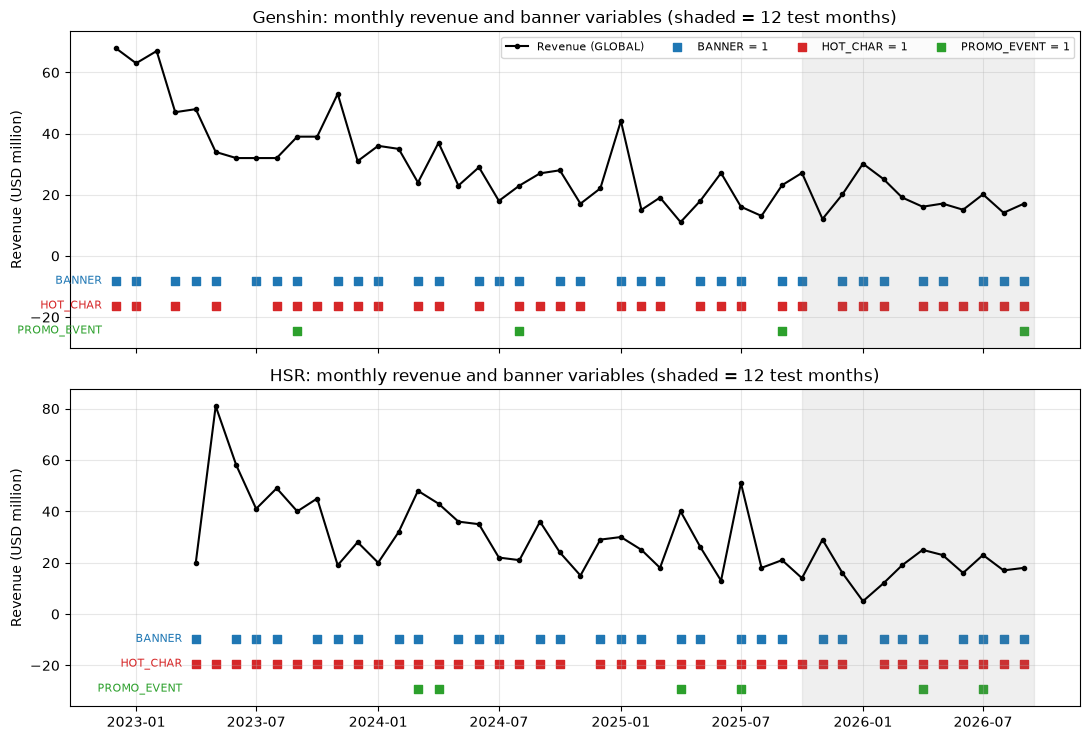

In [11]:
# Revenue and the months in which each banner variable equals 1
VARS = [("BANNER", "#1f77b4"), ("HOT_CHAR", "#d62728"), ("PROMO_EVENT", "#2ca02c")]
fig, axes = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True)
for ax, game in zip(axes, ["Genshin", "HSR"]):
    g = plot_data[plot_data["GAME"] == game]
    ax.plot(g["MONTH"], g["GLOBAL"] / 1e6, color="black", marker="o", ms=3, label="Revenue (GLOBAL)")
    top = g["GLOBAL"].max() / 1e6
    for k, (v, c) in enumerate(VARS):
        on = g[g[v] == 1]
        y = -0.12 * top * (k + 1)
        ax.scatter(on["MONTH"], [y] * len(on), marker="s", s=28, color=c, label=f"{v} = 1")
        ax.text(g["MONTH"].min() - pd.Timedelta(days=20), y, v, ha="right", va="center", fontsize=8, color=c)
    ax.axvspan(pd.Timestamp("2025-10-01"), g["MONTH"].max() + pd.Timedelta(days=15), color="grey", alpha=0.12)
    ax.set_ylim(-0.12 * top * 3.7, top * 1.08)
    ax.set_title(f"{game}: monthly revenue and banner variables (shaded = 12 test months)")
    ax.set_ylabel("Revenue (USD million)")
    ax.grid(alpha=0.3)
axes[0].legend(loc="upper right", fontsize=8, ncol=4)
fig.tight_layout()
fig.savefig(FIG / "variables_timeline.png", dpi=150)
plt.show()

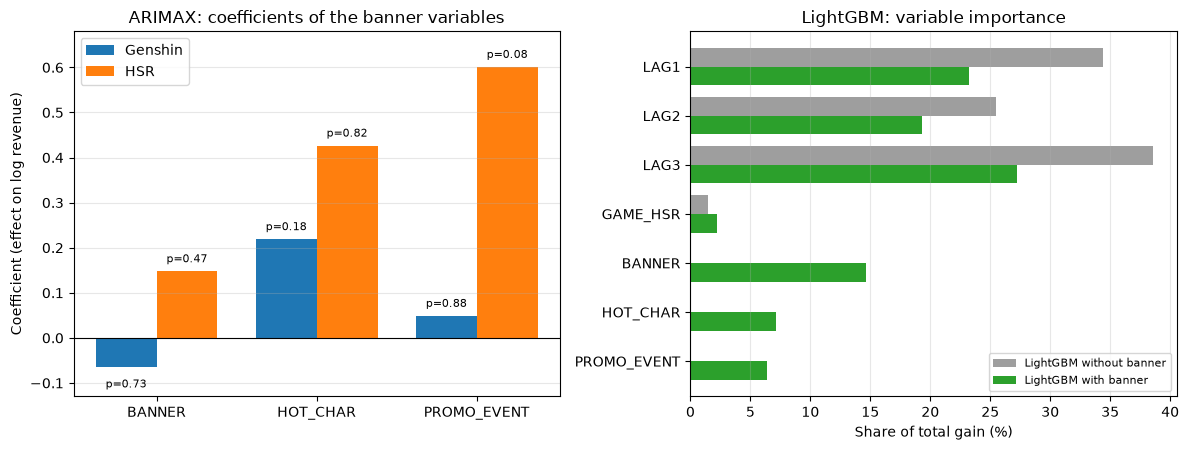

In [12]:
# Contribution of each variable: ARIMAX coefficients and LightGBM gain share
co = pd.read_csv(TAB / "stage5_arimax_coefs.csv")
co = co[co["VARIABLE"] != "LJUNGBOX_P"]
imp_plot = pd.read_csv(TAB / "stage5_lgbm_importance.csv")
names = ["BANNER", "HOT_CHAR", "PROMO_EVENT"]
feats = ["LAG1", "LAG2", "LAG3", "GAME_HSR", "BANNER", "HOT_CHAR", "PROMO_EVENT"]
w = 0.38
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6))
for j, (game, c) in enumerate([("Genshin", "#1f77b4"), ("HSR", "#ff7f0e")]):
    s = co[co["GAME"] == game].set_index("VARIABLE").loc[names]
    xs = [i + (j - 0.5) * w for i in range(3)]
    a1.bar(xs, s["COEF"], w, color=c, label=game)
    for x, cf, p in zip(xs, s["COEF"], s["P_VALUE"]):
        a1.text(x, cf + (0.02 if cf >= 0 else -0.045), f"p={p:.2f}", ha="center", fontsize=8)
a1.axhline(0, color="black", lw=0.8)
a1.set_ylim(-0.13, 0.68)
a1.set_xticks(range(3))
a1.set_xticklabels(names)
a1.set_ylabel("Coefficient (effect on log revenue)")
a1.set_title("ARIMAX: coefficients of the banner variables")
a1.legend()
a1.grid(axis="y", alpha=0.3)
labels = {"LGBM_no_banner": "LightGBM without banner", "LGBM_banner": "LightGBM with banner"}
for j, (m, c) in enumerate([("LGBM_no_banner", "#9e9e9e"), ("LGBM_banner", "#2ca02c")]):
    s = imp_plot[imp_plot["MODEL"] == m].set_index("FEATURE")["GAIN_SHARE_%"]
    ys = [i + (j - 0.5) * w for i in range(len(feats))]
    a2.barh(ys, [s.get(f, 0) for f in feats], w, color=c, label=labels[m])
a2.set_yticks(range(len(feats)))
a2.set_yticklabels(feats)
a2.invert_yaxis()
a2.set_xlabel("Share of total gain (%)")
a2.set_title("LightGBM: variable importance")
a2.legend(fontsize=8)
a2.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "variables_effect.png", dpi=150)
plt.show()